In [ ]:
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [ ]:
# Load dataset and select features
df = pd.read_csv('/content/House_Price_dataset.csv')
df = df[df['purpose'] == 'For Sale']
df = df[['price', 'bedrooms', 'baths', 'Area Size']].dropna()

# Clean data: remove zero values and extreme outliers
df = df[(df['bedrooms'] > 0) & (df['baths'] > 0)]
df = df[df['price'] < df['price'].quantile(0.99)]
df = df[df['Area Size'] < df['Area Size'].quantile(0.99)]

In [ ]:
X=df[['price','bedrooms','baths',"Area Size"]]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
df=df.sample(n=100,random_state=42).reset_index(drop=True)

In [ ]:
X=df[['price','bedrooms','baths',"Area Size"]]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

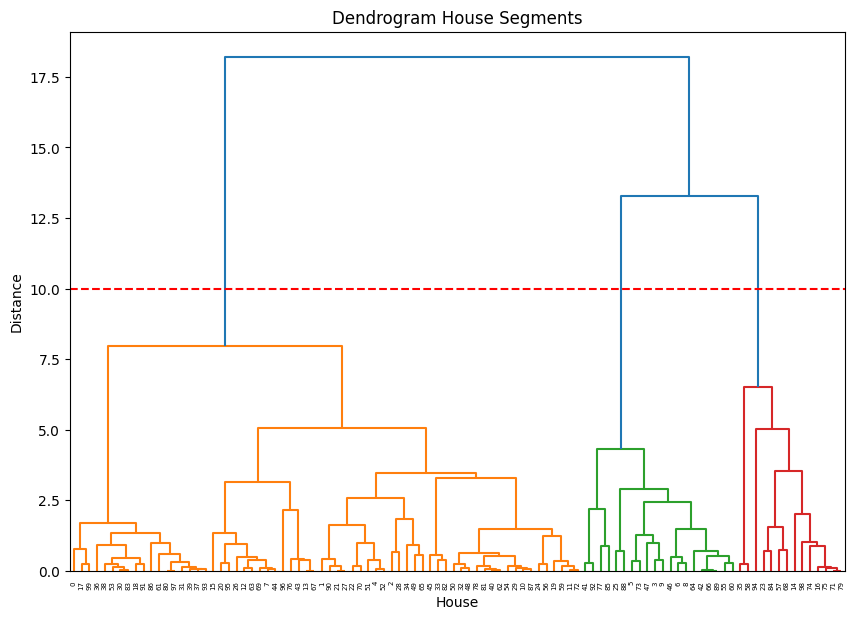

In [ ]:
linked = linkage(X_scaled, 'ward')
plt.figure(figsize=(10, 7))
dendrogram(linked)
plt.title('Dendrogram House Segments')
plt.xlabel('House')
plt.ylabel('Distance')
plt.axhline(y=10, color='red', linestyle='--')
plt.show()

In [ ]:
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')
df["HC_Cluster"] = hc.fit_predict(X_scaled)

In [ ]:
print(df['HC_Cluster'].value_counts())
print(df.groupby('HC_Cluster').mean().round(1))

HC_Cluster
0    66
2    20
1    14
Name: count, dtype: int64
                 price  bedrooms  baths  Area Size
HC_Cluster                                        
0           11235909.1       2.9    2.9        5.1
1           60335714.3       5.6    6.1        1.2
2           26460000.0       4.8    5.2       10.4


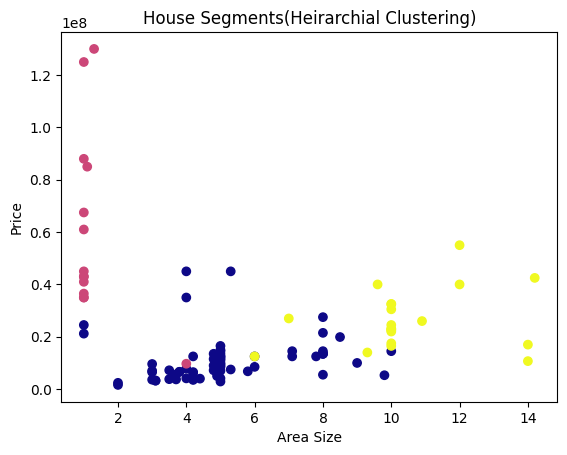

In [ ]:
plt.scatter(df["Area Size"], df["price"], c=df["HC_Cluster"],cmap='plasma')
plt.xlabel("Area Size")
plt.ylabel("Price")
plt.title("House Segments(Heirarchial Clustering)")
plt.show()